# Building processed TILDA image dataset

Process every class folder in `data/` and save the resulting PNGs to the separate `data_processed/` folder. The steps follow the selected pipeline in `TILDA Processing Pipeline.ipynb`: bicubic resize, 8-bit quantization, gamma correction (0.8), per-image min-max contrast stretching, and a 5×5 Gaussian filter.

The output stays at 64×64 so it matches the compact CNN input described in the project reports. The existing exploration notebook upsamples examples to 224×224, but upsampling does not add image detail and would require changing the model input design. This notebook processes the full dataset rather than one sample per class.

Run the cells from top to bottom. The source `data/` folder is read-only from this workflow; processed files are written alongside it in `data_processed/<class>/`.

In [6]:
!pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)


In [7]:
from pathlib import Path
from collections import Counter
import numpy as np
import cv2
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'data').is_dir() and (candidate / 'notebooks').is_dir():
            return candidate
    raise FileNotFoundError('Could not find the project root containing data/ and notebooks/.')

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'data_processed'
IMAGE_SUFFIXES = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
TARGET_SIZE = (64, 64)  # width, height; preserve the model's documented input size
GAMMA = 0.8
GAUSSIAN_KERNEL = (5, 5)

if DATA_DIR.resolve() == OUTPUT_DIR.resolve():
    raise ValueError('Input and output folders must be different.')
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Dataset folder not found: {DATA_DIR}')

class_dirs = sorted(path for path in DATA_DIR.iterdir() if path.is_dir())
if not class_dirs:
    raise FileNotFoundError(f'No class folders found in {DATA_DIR}')

print(f'Project: {PROJECT_ROOT}')
print(f'Input:   {DATA_DIR}')
print(f'Output:  {OUTPUT_DIR}')
print('Classes:', ', '.join(path.name for path in class_dirs))

Project: E:\Ganesh Sarathi\College\Coding\DIP\Fabric Defect Detection\FabricDefectDetectionDIP
Input:   E:\Ganesh Sarathi\College\Coding\DIP\Fabric Defect Detection\FabricDefectDetectionDIP\data
Output:  E:\Ganesh Sarathi\College\Coding\DIP\Fabric Defect Detection\FabricDefectDetectionDIP\data_processed
Classes: good, hole, objects, oil spot, thread error


## Processing steps

Eight-bit quantization is retained for consistency with the exploratory notebook; for 8-bit PNG inputs it does not reduce precision. Gamma correction uses the same inverse-gamma lookup table as that notebook. Min-max stretching and Gaussian smoothing are applied per image, matching its selected enhancement pipeline.

In [8]:
def quantize(image: np.ndarray, bits: int = 8) -> np.ndarray:
    levels = 2 ** bits
    step = 256 / levels
    return (np.floor(image.astype(np.float32) / step) * step).clip(0, 255).astype(np.uint8)

def preprocess_image(image: Image.Image) -> np.ndarray:
    image = ImageOps.exif_transpose(image).convert('RGB')
    image = image.resize(TARGET_SIZE, resample=Image.Resampling.BICUBIC)
    array = quantize(np.asarray(image), bits=8)

    # Match the gamma lookup-table operation in the existing pipeline notebook.
    inverse_gamma = 1.0 / GAMMA
    lut = np.array([((value / 255.0) ** inverse_gamma) * 255 for value in range(256)], dtype=np.uint8)
    array = cv2.LUT(array, lut)

    # Min-max contrast stretch per image, as in the selected exploratory pipeline.
    array = cv2.normalize(array, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)

    # 5x5 Gaussian smoothing, as in the selected exploratory pipeline.
    array = cv2.GaussianBlur(array, GAUSSIAN_KERNEL, sigmaX=0)
    return array

print('Preprocessing function is ready.')

Preprocessing function is ready.


## Process all images

Each input class folder is mirrored under `data_processed/`. Output files use PNG format and keep the source filename stem. Running this cell again overwrites matching outputs and leaves the original dataset untouched.

In [9]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
processed_counts = Counter()
source_counts = Counter()
failures = []

for class_dir in class_dirs:
    image_paths = sorted(
        path for path in class_dir.rglob('*')
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    source_counts[class_dir.name] = len(image_paths)

    for image_path in image_paths:
        relative_path = image_path.relative_to(DATA_DIR)
        output_path = (OUTPUT_DIR / relative_path).with_suffix('.png')
        output_path.parent.mkdir(parents=True, exist_ok=True)
        try:
            with Image.open(image_path) as source_image:
                processed = preprocess_image(source_image)
            Image.fromarray(processed, mode='RGB').save(output_path, format='PNG')
            processed_counts[class_dir.name] += 1
        except Exception as exc:
            failures.append((str(image_path), repr(exc)))

print(f'Processed {sum(processed_counts.values()):,} of {sum(source_counts.values()):,} input images.')
for class_name in sorted(source_counts):
    print(f'{class_name:16} {processed_counts[class_name]:>6,} / {source_counts[class_name]:,}')
if failures:
    print(f'\nFailed images: {len(failures)}')
    for path, error in failures[:20]:
        print(f'- {path}: {error}')
    if len(failures) > 20:
        print(f'... and {len(failures) - 20} more')
    raise RuntimeError('Processing did not finish cleanly; review the failure list above.')
if processed_counts != source_counts:
    raise RuntimeError('Processed image counts do not match source counts.')

print(f'\nProcessed images saved in: {OUTPUT_DIR}')

Processed 25,600 of 25,600 input images.
good             23,170 / 23,170
hole                337 / 337
objects             837 / 837
oil spot            636 / 636
thread error        620 / 620

Processed images saved in: E:\Ganesh Sarathi\College\Coding\DIP\Fabric Defect Detection\FabricDefectDetectionDIP\data_processed


## Preview one source/output pair per class

Use this visual check to confirm that outputs look sensible before training. The Gaussian filter and per-image contrast stretch may change subtle defect texture, so compare validation results with a raw-image baseline. For evaluation, keep related patches from a source fabric image in the same split; do not split neighboring patches randomly across train and test.

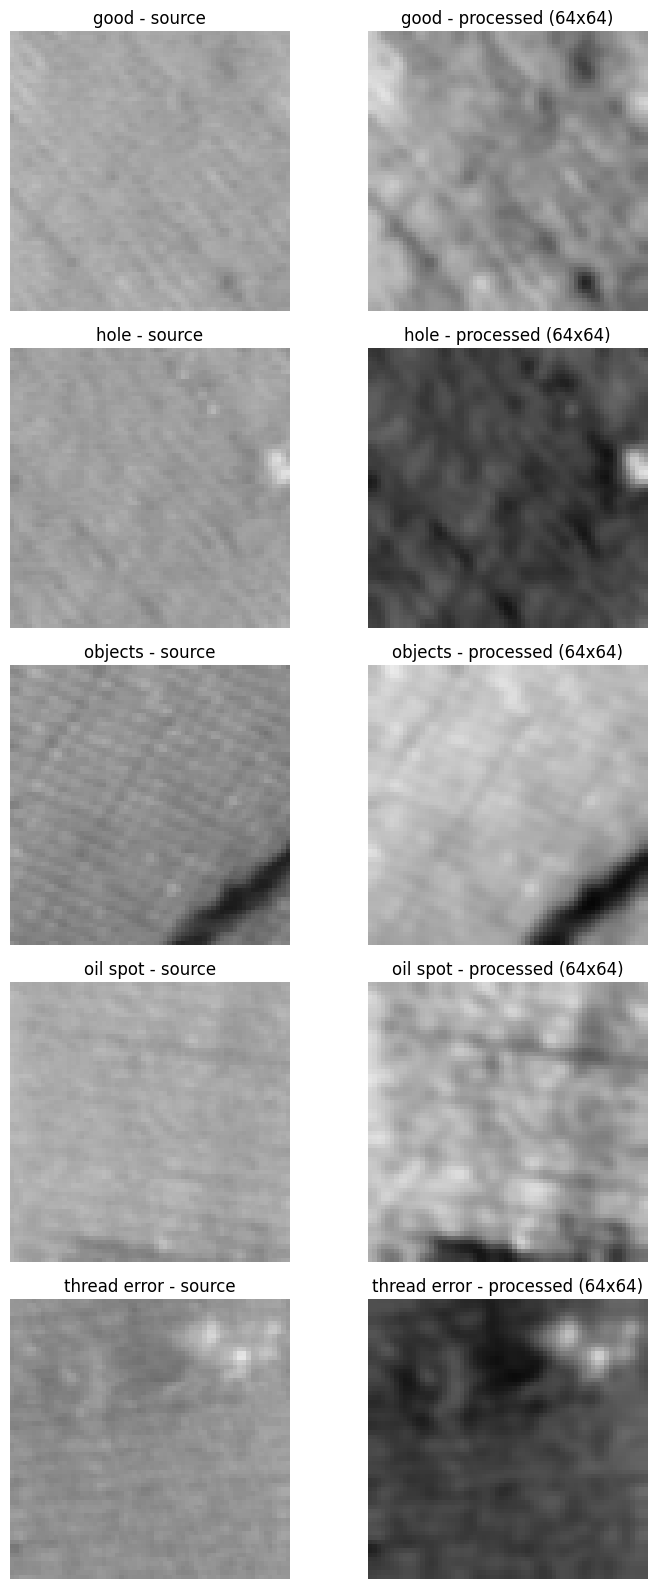

In [10]:
fig, axes = plt.subplots(len(class_dirs), 2, figsize=(8, 3.2 * len(class_dirs)), squeeze=False)
for row, class_dir in enumerate(class_dirs):
    candidates = sorted(
        path for path in class_dir.rglob('*')
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    if not candidates:
        axes[row, 0].axis('off')
        axes[row, 1].axis('off')
        axes[row, 0].set_title(f'{class_dir.name}: no images')
        continue
    source_path = candidates[0]
    output_path = (OUTPUT_DIR / source_path.relative_to(DATA_DIR)).with_suffix('.png')
    with Image.open(source_path) as source_image:
        axes[row, 0].imshow(ImageOps.exif_transpose(source_image).convert('RGB'))
    axes[row, 0].set_title(f'{class_dir.name} - source')
    axes[row, 0].axis('off')
    with Image.open(output_path) as processed_image:
        axes[row, 1].imshow(processed_image.convert('RGB'))
    axes[row, 1].set_title(f'{class_dir.name} - processed (64x64)')
    axes[row, 1].axis('off')
plt.tight_layout()
plt.show()